# From Text Corpus to Training Sequences
### Train a tiny tokenizer, encode documents, and prepare next-token examples

> **Learning objective:** Turn prepared text documents into numerical sequences that a decoder-only Transformer can consume during pretraining.

This notebook connects the previous topics:
- **Tokenization:** how text becomes token IDs.
- **Training data:** how documents are cleaned, deduplicated, filtered, and split.

We will now build the bridge between them.

### Notebook map

1. Load the prepared corpus
2. Understand the tokenizer-to-model pipeline
3. Train a small BPE tokenizer on the training split only
4. Add special tokens
5. Encode documents into token IDs
6. Understand end-of-document markers
7. Create fixed-length next-token examples
8. Understand input/target shifting
9. Pad examples into batches and build loss masks
10. Inspect the final training tensors
11. Understand sequence packing and data leakage
12. Save the tokenized dataset and tokenizer metadata

### Important scope note

We will use a compact **educational word-boundary BPE tokenizer** similar in spirit to the previous notebook. It is not an exact implementation of GPT-2, Llama, Qwen, or another production tokenizer. The purpose here is to understand the data flow and training-example construction.

## 1. Load the prepared corpus

In the previous notebook, we saved:

```text
prepared_corpus/
├── train.jsonl
├── validation.jsonl
├── test.jsonl
└── dataset_manifest.json
```

This notebook will load those files if they exist. If they are not present, we will create a small synthetic fallback corpus so the notebook remains runnable on its own.

**For your actual repository workflow:** run Notebook 03 first, then run this notebook from the same project directory.

In [2]:
import re
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

DATA_DIR = Path("prepared_corpus")
EXPECTED_COLUMNS = ["doc_id", "source", "license", "language", "text"]

def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            if line.strip():
                records.append(json.loads(line))
    return pd.DataFrame(records, columns=EXPECTED_COLUMNS)

required_files = [
    DATA_DIR / "train.jsonl",
    DATA_DIR / "validation.jsonl",
    DATA_DIR / "test.jsonl"
]

use_fallback = not all(path.exists() for path in required_files)

if not use_fallback:
    train_df = read_jsonl(required_files[0])
    validation_df = read_jsonl(required_files[1])
    test_df = read_jsonl(required_files[2])

    # Tiny demo corpora can produce empty splits. Use a balanced fallback
    # rather than silently proceeding with a missing or unusable split.
    use_fallback = (
        train_df.empty
        or validation_df.empty
        or test_df.empty
        or "text" not in train_df.columns
    )

if use_fallback:
    print(
        "Prepared corpus is missing or has an empty split. "
        "Using a self-contained synthetic fallback."
    )
    fallback_docs = [
        "A language model predicts the next token from preceding context.",
        "A tokenizer converts text into tokens and maps tokens to integer IDs.",
        "A transformer uses attention to mix information across sequence positions.",
        "Training adjusts model parameters to reduce the next token prediction loss.",
        "A training corpus contains documents used to teach a language model.",
        "Validation data helps measure how well a model generalizes to unseen text.",
        "A decoder only transformer uses causal attention for autoregressive generation.",
        "Token embeddings convert token identifiers into vectors of numbers.",
        "The context length determines how many tokens the model can process together.",
        "A dataset should be cleaned and split before creating training sequences.",
        "The model receives input tokens and learns to predict the following tokens.",
        "Small language models can be trained with carefully prepared data and compute."
    ]
    fallback = pd.DataFrame({
        "doc_id": [f"fallback_{i:03d}" for i in range(len(fallback_docs))],
        "source": ["synthetic_fallback"] * len(fallback_docs),
        "license": ["synthetic_demo"] * len(fallback_docs),
        "language": ["en"] * len(fallback_docs),
        "text": fallback_docs
    })
    train_df = fallback.iloc[:9].reset_index(drop=True)
    validation_df = fallback.iloc[9:11].reset_index(drop=True)
    test_df = fallback.iloc[11:].reset_index(drop=True)

for name, frame in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df)
]:
    if "text" not in frame.columns:
        raise ValueError(f"The {name} split must contain a 'text' column.")
    frame["text"] = frame["text"].fillna("").astype(str).str.strip()

print("Train documents:", len(train_df))
print("Validation documents:", len(validation_df))
print("Test documents:", len(test_df))

display(train_df.head())

Train documents: 7
Validation documents: 1
Test documents: 1

,doc_id,source,license,language,text
0,d10,technology,synthetic_demo,en,A neural network is made from layers of connec...
1,d02,education,synthetic_demo,en,Tokenization converts text into smaller units ...
2,d08,noise,synthetic_demo,en,click here click here click here click here cl...
3,d01,education,synthetic_demo,en,A language model learns patterns in text by pr...
4,d12,education,synthetic_demo,en,The training corpus should be split by documen...


### Inspect the split sizes

A small demonstration corpus may have only a few validation or test documents. That is fine for learning the pipeline, but it is not enough for a reliable estimate of model quality.

In [3]:
split_stats = pd.DataFrame([
    {"split": "train", "documents": len(train_df),
     "words": int(train_df["text"].str.split().str.len().sum())},
    {"split": "validation", "documents": len(validation_df),
     "words": int(validation_df["text"].str.split().str.len().sum())},
    {"split": "test", "documents": len(test_df),
     "words": int(test_df["text"].str.split().str.len().sum())}
])
display(split_stats)

,split,documents,words
0,train,7,86
1,validation,1,13
2,test,1,14


## 2. The pipeline: from documents to model examples

The model does not consume a Pandas DataFrame or a paragraph of raw text. We transform each document into a sequence of integer token IDs, then create input/target pairs.

```text
Prepared documents
      │
      ▼
Tokenizer (trained on training text only)
      │
      ▼
Token IDs + end-of-document token
      │
      ▼
Fixed-length chunks
      │
      ├── Input:  [t0, t1, t2, t3]
      │
      └── Target: [t1, t2, t3, t4]
                    │
                    ▼
             Model training batch
```

The target at each position is the **next token**. We will derive this carefully below.

## 3. Train a small BPE tokenizer on the training split

A crucial rule: train the tokenizer using the **training split only**. Do not use validation or test text to learn the vocabulary or merge rules. This keeps the evaluation splits separate from tokenizer fitting.

For this teaching implementation:
- We split text on whitespace into words.
- Each word starts as characters plus `</w>`.
- We count adjacent symbol pairs, weighted by word frequency.
- We repeatedly merge the most frequent pair.

This is intentionally simpler than production tokenizers, which may use byte-level input, regex pre-tokenization, normalization, and special handling.

In [4]:
END_OF_WORD = "</w>"

def initial_symbols(word):
    return tuple(list(word) + [END_OF_WORD])

def count_pairs(sequences, frequencies):
    pair_counts = Counter()
    for word, symbols in sequences.items():
        for i in range(len(symbols) - 1):
            pair_counts[(symbols[i], symbols[i + 1])] += frequencies[word]
    return pair_counts

def merge_pair(sequence, pair):
    output = []
    i = 0
    while i < len(sequence):
        if (
            i + 1 < len(sequence)
            and sequence[i] == pair[0]
            and sequence[i + 1] == pair[1]
        ):
            output.append(pair[0] + pair[1])
            i += 2
        else:
            output.append(sequence[i])
            i += 1
    return tuple(output)

def train_word_bpe(texts, num_merges=40):
    word_frequencies = Counter()
    for text in texts:
        word_frequencies.update(text.split())

    sequences = {
        word: initial_symbols(word)
        for word in word_frequencies
    }

    merges = []
    history = []

    for step in range(num_merges):
        pair_counts = count_pairs(sequences, word_frequencies)
        if not pair_counts:
            break

        best_pair, frequency = pair_counts.most_common(1)[0]
        sequences = {
            word: merge_pair(symbols, best_pair)
            for word, symbols in sequences.items()
        }

        merges.append(best_pair)
        history.append({
            "step": step + 1,
            "left": best_pair[0],
            "right": best_pair[1],
            "merged_token": best_pair[0] + best_pair[1],
            "frequency": frequency
        })

    return merges, sequences, pd.DataFrame(history), word_frequencies

train_texts = train_df["text"].tolist()

merges, trained_word_sequences, merge_history, train_word_frequencies = (
    train_word_bpe(train_texts, num_merges=40)
)

print("Number of learned merges:", len(merges))
display(merge_history.head(15))

Number of learned merges: 40

,step,left,right,merged_token,frequency
0,1,s,</w>,s</w>,15
1,2,e,r,er,14
2,3,i,n,in,14
3,4,e,</w>,e</w>,12
4,5,o,n,on,11
5,6,o,r,or,9
6,7,a,l,al,8
7,8,a,t,at,8
8,9,i,c,ic,7
9,10,.,</w>,.</w>,7


### Inspect the learned merge rules

The tokenizer has learned reusable subword units from frequent character sequences in the training text.

The exact merge order depends on the corpus and tie-breaking behavior. The important part is that the merge list is **ordered** and must be preserved for encoding.

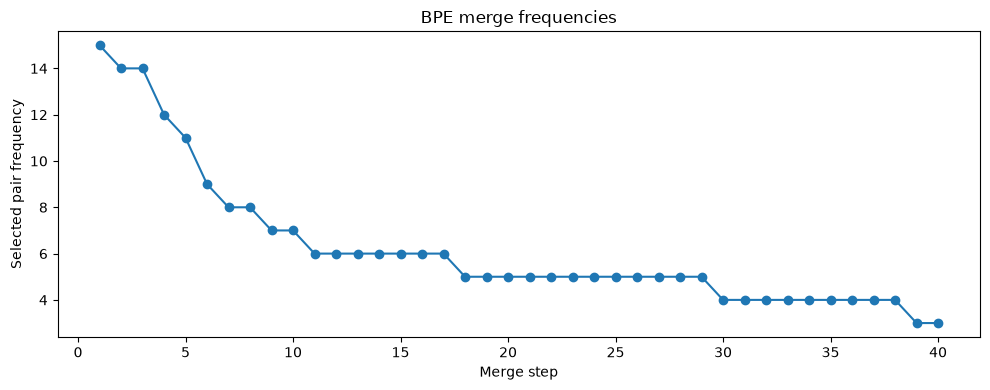

In [5]:
if not merge_history.empty:
    plt.figure(figsize=(10, 4))
    plt.plot(merge_history["step"], merge_history["frequency"], marker="o")
    plt.xlabel("Merge step")
    plt.ylabel("Selected pair frequency")
    plt.title("BPE merge frequencies")
    plt.tight_layout()
    plt.show()
else:
    print("No merges were learned; inspect the training text.")

## 4. Build the tokenizer vocabulary and special tokens

A tokenizer usually reserves specific IDs for special tokens. Their exact set depends on the model.

For this notebook, we will use:

| Special token | Purpose |
|---|---|
| `<pad>` | Padding shorter sequences in a batch |
| `<unk>` | Fallback for a symbol not in the tokenizer alphabet |
| `<eos>` | Marks the end of a document |
| `<bos>` | Optional beginning-of-sequence marker |

We will include `<eos>` in our document encoding. We will define `<bos>` for completeness, but our basic next-token examples do not require it.

**Special tokens must have stable, reserved IDs.** Do not let ordinary text accidentally be interpreted as one of these markers.

In [6]:
# Collect symbols that occur in the final training representations.
learned_symbols = set()
for symbols in trained_word_sequences.values():
    learned_symbols.update(symbols)

# Include initial alphabet symbols so unseen combinations can still be represented
# as character pieces when those characters occurred in training.
training_alphabet = {
    char
    for word in train_word_frequencies
    for char in word
}
base_symbols = set(training_alphabet) | {END_OF_WORD}

# Add all merge products.
for left, right in merges:
    base_symbols.add(left)
    base_symbols.add(right)
    base_symbols.add(left + right)

SPECIAL_TOKENS = ["<pad>", "<unk>", "<eos>", "<bos>"]

ordinary_tokens = sorted(
    token for token in (learned_symbols | base_symbols)
    if token not in SPECIAL_TOKENS
)

vocabulary = SPECIAL_TOKENS + ordinary_tokens
token_to_id = {token: idx for idx, token in enumerate(vocabulary)}
id_to_token = {idx: token for token, idx in token_to_id.items()}

PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
EOS_ID = token_to_id["<eos>"]
BOS_ID = token_to_id["<bos>"]

print("Vocabulary size:", len(vocabulary))
print("Special token IDs:", {
    token: token_to_id[token] for token in SPECIAL_TOKENS
})

display(pd.DataFrame({
    "token": vocabulary[:30],
    "token_id": [token_to_id[token] for token in vocabulary[:30]]
}))

Vocabulary size: 79
Special token IDs: {'<pad>': 0, '<unk>': 1, '<eos>': 2, '<bos>': 3}

,token,token_id
0,<pad>,0
1,<unk>,1
2,<eos>,2
3,<bos>,3
4,.,4
5,.</w>,5
6,/,6
7,:,7
8,</w>,8
9,A,9


## 5. Encode words and documents

To encode a word:
1. Start with its characters plus `</w>`.
2. Apply every learned merge in the same order used during training.
3. Convert the resulting pieces to token IDs.
4. If an individual symbol is unknown, map it to `<unk>`.

We then append `<eos>` to each document so the model can learn where a document ends.

In [7]:
def bpe_encode_word(word, merge_rules):
    symbols = initial_symbols(word)
    for pair in merge_rules:
        symbols = merge_pair(symbols, pair)
    return list(symbols)

def encode_document(text, merge_rules, token_to_id, eos_id):
    ids = []
    for word in text.split():
        pieces = bpe_encode_word(word, merge_rules)
        ids.extend(token_to_id.get(piece, UNK_ID) for piece in pieces)
    ids.append(eos_id)
    return ids

def decode_word_pieces(pieces):
    combined = "".join(pieces)
    if combined.endswith(END_OF_WORD):
        combined = combined[:-len(END_OF_WORD)]
    return combined

example_text = train_texts[0]
example_words = example_text.split()
example_pieces = [bpe_encode_word(word, merges) for word in example_words]
example_ids = encode_document(example_text, merges, token_to_id, EOS_ID)

print("Text:", example_text)
print("Word pieces:", example_pieces)
print("Token IDs:", example_ids)
print("Decoded word pieces:", " ".join(decode_word_pieces(p) for p in example_pieces))

Text: A neural network is made from layers of connected computational units that transform numerical inputs.
Word pieces: [['A</w>'], ['ne', 'ur', 'al</w>'], ['ne', 't', 'w', 'or', 'k</w>'], ['i', 's</w>'], ['m', 'a', 'd', 'e</w>'], ['f', 'r', 'om', '</w>'], ['la', 'y', 'er', 's</w>'], ['o', 'f', '</w>'], ['con', 'ne', 'c', 'te', 'd</w>'], ['c', 'om', 'pu', 't', 'ation', 'al</w>'], ['unit', 's</w>'], ['th', 'at', '</w>'], ['tr', 'a', 'n', 's', 'for', 'm', '</w>'], ['n', 'u', 'm', 'er', 'ic', 'al</w>'], ['in', 'pu', 't', 's.</w>']]
Token IDs: [10, 51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49, 16, 28, 31, 33, 60, 54, 8, 48, 77, 32, 63, 53, 33, 8, 27, 51, 23, 66, 29, 23, 54, 58, 64, 21, 18, 72, 63, 67, 19, 8, 69, 16, 50, 61, 34, 49, 8, 50, 70, 49, 32, 40, 18, 41, 58, 64, 62, 2]
Decoded word pieces: A neural network is made from layers of connected computational units that transform numerical inputs.

### Why do we append `<eos>`?

When multiple documents are processed in sequence, an end-of-document marker provides a boundary signal. It teaches the model that one document ended.

It does **not automatically guarantee document isolation**: if documents are packed together, later tokens may still attend to earlier documents unless the attention mask or packing strategy prevents that. We will discuss this later.

## 6. Encode all splits using the same tokenizer

The tokenizer is fitted only on training text. We now apply those exact merge rules and vocabulary IDs to train, validation, and test documents.

Do not train separate tokenizers for validation or test: that would give the same token ID different meanings across splits and would leak information from evaluation data into tokenizer fitting.

In [8]:
def encode_split(frame, split_name):
    records = []
    for _, row in frame.iterrows():
        ids = encode_document(
            row["text"], merges, token_to_id, EOS_ID
        )
        records.append({
            "doc_id": row.get("doc_id", f"{split_name}_{len(records)}"),
            "split": split_name,
            "text": row["text"],
            "token_ids": ids,
            "token_count": len(ids)
        })
    return pd.DataFrame(records)

train_encoded = encode_split(train_df, "train")
validation_encoded = encode_split(validation_df, "validation")
test_encoded = encode_split(test_df, "test")

display(train_encoded[["doc_id", "token_count", "token_ids"]].head())

,doc_id,token_count,token_ids
0,d10,60,"[10, 51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 4..."
1,d02,63,"[14, 53, 46, 52, 78, 21, 8, 27, 74, 32, 64, 63..."
2,d08,11,"[26, 38, 26, 38, 26, 38, 26, 38, 26, 38, 2]"
3,d01,67,"[10, 48, 50, 35, 70, 16, 35, 31, 49, 53, 28, 3..."
4,d12,65,"[14, 36, 31, 69, 16, 41, 43, 23, 56, 58, 63, 6..."


### Compare token counts

Tokenization changes document length. We can inspect how many tokens each document contains and how token count compares with word count.

,doc_id,word_count,token_count,tokens_per_word
0,d10,15,60,4.000000
1,d02,16,63,3.937500
2,d08,10,11,1.100000
3,d01,14,67,4.785714
4,d12,13,65,5.000000
5,d03,10,47,4.700000
6,d07,8,51,6.375000


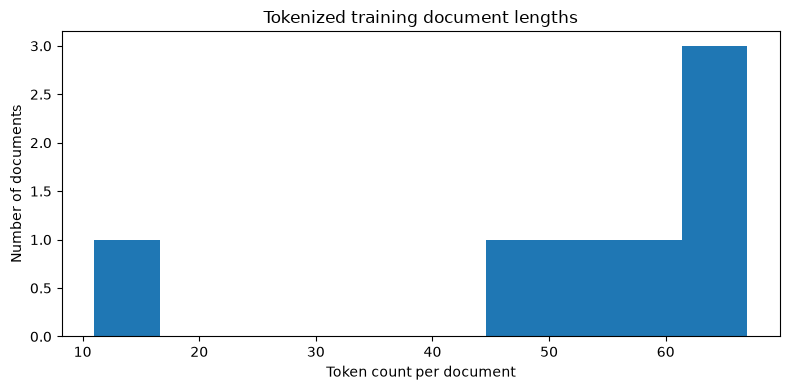

In [9]:
def add_word_counts(frame):
    result = frame.copy()
    result["word_count"] = result["text"].str.split().str.len()
    result["tokens_per_word"] = (
        result["token_count"] / result["word_count"].replace(0, np.nan)
    )
    return result

train_encoded_stats = add_word_counts(train_encoded)
display(train_encoded_stats[[
    "doc_id", "word_count", "token_count", "tokens_per_word"
]])

plt.figure(figsize=(8, 4))
plt.hist(train_encoded_stats["token_count"], bins=10)
plt.xlabel("Token count per document")
plt.ylabel("Number of documents")
plt.title("Tokenized training document lengths")
plt.tight_layout()
plt.show()

## 7. Context length: how many tokens can the model process?

A Transformer is trained on sequences with a chosen maximum length, often called the **context length** or **sequence length**.

For example, if the context length is 128, one training example contains at most 128 input positions.

A context length is a design choice that affects:
- How much preceding text the model can use
- Memory use
- Attention computation
- Training throughput

For this tiny demonstration, we will use a small block size so examples are easy to inspect.

In [10]:
BLOCK_SIZE = 12

print("Block size / context length:", BLOCK_SIZE)

Block size / context length: 12

## 8. Create next-token training examples

This is the central operation in autoregressive language-model pretraining.

Suppose a tokenized sequence is:

```text
[ A, B, C, D, E ]
```

The model input is:

```text
[ A, B, C, D ]
```

The target is:

```text
[ B, C, D, E ]
```

At each position, the target is the **next token**.

Mathematically, if the sequence is \(x_1, x_2, \ldots, x_T\):

\[
\text{input} = (x_1, x_2, \ldots, x_{T-1})
\]

\[
\text{target} = (x_2, x_3, \ldots, x_T)
\]

The model predicts all next-token targets in parallel during training, while causal attention prevents it from looking at future input positions.

In [11]:
toy_ids = [10, 11, 12, 13, 14]

toy_input = toy_ids[:-1]
toy_target = toy_ids[1:]

print("Full sequence:", toy_ids)
print("Input:        ", toy_input)
print("Target:       ", toy_target)

assert toy_input == [10, 11, 12, 13]
assert toy_target == [11, 12, 13, 14]

Full sequence: [10, 11, 12, 13, 14]
Input:         [10, 11, 12, 13]
Target:        [11, 12, 13, 14]

### Build chunks from each document

We will create chunks **within each document**, so a chunk does not silently continue into the next document.

For a block size of 12:
- Each input can contain up to 12 tokens.
- Its target contains the following token at each position.
- A chunk may contain up to 13 tokens before shifting.

We will keep shorter final chunks and pad them later when creating batches.

In [12]:
def make_next_token_examples(encoded_frame, block_size):
    examples = []

    for _, row in encoded_frame.iterrows():
        ids = row["token_ids"]

        # Each chunk needs at least two tokens to create one input/target pair.
        for start in range(0, len(ids) - 1, block_size):
            chunk = ids[start:start + block_size + 1]

            if len(chunk) < 2:
                continue

            examples.append({
                "doc_id": row["doc_id"],
                "input_ids": chunk[:-1],
                "target_ids": chunk[1:],
                "input_length": len(chunk) - 1
            })

    return pd.DataFrame(examples)

train_examples = make_next_token_examples(train_encoded, BLOCK_SIZE)
validation_examples = make_next_token_examples(validation_encoded, BLOCK_SIZE)
test_examples = make_next_token_examples(test_encoded, BLOCK_SIZE)

print("Training examples:", len(train_examples))
print("Validation examples:", len(validation_examples))
print("Test examples:", len(test_examples))

display(train_examples.head())

Training examples: 33
Validation examples: 6
Test examples: 6

,doc_id,input_ids,target_ids,input_length
0,d10,"[10, 51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49]","[51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49, 16]",12
1,d10,"[16, 28, 31, 33, 60, 54, 8, 48, 77, 32, 63, 53]","[28, 31, 33, 60, 54, 8, 48, 77, 32, 63, 53, 33]",12
2,d10,"[33, 8, 27, 51, 23, 66, 29, 23, 54, 58, 64, 21]","[8, 27, 51, 23, 66, 29, 23, 54, 58, 64, 21, 18]",12
3,d10,"[18, 72, 63, 67, 19, 8, 69, 16, 50, 61, 34, 49]","[72, 63, 67, 19, 8, 69, 16, 50, 61, 34, 49, 8]",12
4,d10,"[8, 50, 70, 49, 32, 40, 18, 41, 58, 64, 62]","[50, 70, 49, 32, 40, 18, 41, 58, 64, 62, 2]",11


### Verify the shift

For every example, the target should be the input shifted one token to the left in the original unshifted chunk.

We can check that the target length equals the input length and that the values align.

In [13]:
for _, example in train_examples.head(5).iterrows():
    assert len(example["input_ids"]) == len(example["target_ids"])
    print("Input: ", example["input_ids"])
    print("Target:", example["target_ids"])
    print()

Input:  [10, 51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49]
Target: [51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49, 16]

Input:  [16, 28, 31, 33, 60, 54, 8, 48, 77, 32, 63, 53]
Target: [28, 31, 33, 60, 54, 8, 48, 77, 32, 63, 53, 33]

Input:  [33, 8, 27, 51, 23, 66, 29, 23, 54, 58, 64, 21]
Target: [8, 27, 51, 23, 66, 29, 23, 54, 58, 64, 21, 18]

Input:  [18, 72, 63, 67, 19, 8, 69, 16, 50, 61, 34, 49]
Target: [72, 63, 67, 19, 8, 69, 16, 50, 61, 34, 49, 8]

Input:  [8, 50, 70, 49, 32, 40, 18, 41, 58, 64, 62]
Target: [50, 70, 49, 32, 40, 18, 41, 58, 64, 62, 2]

## 9. Padding examples into a batch

Neural-network operations are most convenient when examples in a batch have the same shape.

But our final chunks may be shorter than the block size. We can pad them using `<pad>`.

We also create a **loss mask**:
- `1` means this target position contributes to the loss.
- `0` means this position is padding and must be ignored.

Padding is not a real next-token target. If we included padding positions in the loss, the model would waste effort learning to predict `<pad>` where no real token exists.

In [14]:
def make_batch(examples, indices, block_size, pad_id):
    batch_examples = examples.iloc[indices]

    batch_size = len(batch_examples)
    x_batch = np.full((batch_size, block_size), pad_id, dtype=np.int64)
    y_batch = np.full((batch_size, block_size), pad_id, dtype=np.int64)
    loss_mask = np.zeros((batch_size, block_size), dtype=np.float32)

    for row_index, (_, example) in enumerate(batch_examples.iterrows()):
        x = example["input_ids"]
        y = example["target_ids"]
        length = min(len(x), block_size)

        x_batch[row_index, :length] = x[:length]
        y_batch[row_index, :length] = y[:length]
        loss_mask[row_index, :length] = 1.0

    return x_batch, y_batch, loss_mask

if len(train_examples) > 0:
    selected_indices = list(range(min(3, len(train_examples))))
    X_batch, Y_batch, loss_mask = make_batch(
        train_examples, selected_indices, BLOCK_SIZE, PAD_ID
    )

    print("X batch shape:", X_batch.shape)
    print("Y batch shape:", Y_batch.shape)
    print("Loss mask shape:", loss_mask.shape)

    print("\nInputs:\n", X_batch)
    print("\nTargets:\n", Y_batch)
    print("\nLoss mask:\n", loss_mask)
else:
    print("No training examples were created. Inspect corpus size and tokenization.")

X batch shape: (3, 12)
Y batch shape: (3, 12)
Loss mask shape: (3, 12)

Inputs:
 [[10 51 73 18 51 64 75 56 45 39 63 49]
 [16 28 31 33 60 54  8 48 77 32 63 53]
 [33  8 27 51 23 66 29 23 54 58 64 21]]

Targets:
 [[51 73 18 51 64 75 56 45 39 63 49 16]
 [28 31 33 60 54  8 48 77 32 63 53 33]
 [ 8 27 51 23 66 29 23 54 58 64 21 18]]

Loss mask:
 [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]

### Understand the shapes

For batch size \(B\) and block size \(T\):

\[
X \in \mathbb{N}^{B \times T}
\]

\[
Y \in \mathbb{N}^{B \times T}
\]

\[
M \in \{0,1\}^{B \times T}
\]

Here:
- \(X\) contains input token IDs.
- \(Y\) contains next-token target IDs.
- \(M\) indicates which target positions are valid.

The Transformer will turn each input ID into a vector, and its output layer will produce vocabulary logits at every position.

## 10. Visualize a training example

Let's show one example as token strings, not just integer IDs. This makes the shift easier to understand.

Remember that our tokenizer uses subword pieces and an end-of-word marker. A piece ending in `</w>` marks the end of a word in this educational tokenizer.

In [15]:
def ids_to_pieces(ids):
    return [id_to_token.get(int(token_id), "<invalid>") for token_id in ids]

if len(train_examples) > 0:
    example = train_examples.iloc[0]
    print("Document:", example["doc_id"])
    print("Input IDs: ", example["input_ids"])
    print("Input pieces:", ids_to_pieces(example["input_ids"]))
    print()
    print("Target IDs:", example["target_ids"])
    print("Target pieces:", ids_to_pieces(example["target_ids"]))

Document: d10
Input IDs:  [10, 51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49]
Input pieces: ['A</w>', 'ne', 'ur', 'al</w>', 'ne', 't', 'w', 'or', 'k</w>', 'i', 's</w>', 'm']

Target IDs: [51, 73, 18, 51, 64, 75, 56, 45, 39, 63, 49, 16]
Target pieces: ['ne', 'ur', 'al</w>', 'ne', 't', 'w', 'or', 'k</w>', 'i', 's</w>', 'm', 'a']

## 11. Sequence packing and document boundaries

When documents are short, training each one separately can leave unused space in the final chunk. A common optimization is **sequence packing**: concatenate multiple documents into a longer token stream, usually placing an end-of-document token between them.

Example:

```text
Document A: [a, b, c, <eos>]
Document B: [d, e, f, <eos>]

Packed stream:
[a, b, c, <eos>, d, e, f, <eos>]
```

Packing improves utilization, but there is an important modeling detail:

**A normal causal mask allows later document tokens to attend to earlier document tokens in the same packed sequence.** The `<eos>` token marks a boundary but does not itself block attention.

If strict document isolation is required, use a block-diagonal or document-aware attention mask, or use a packing strategy that prevents cross-document attention. Some training setups deliberately allow cross-document context after separators; the right choice depends on the training recipe.

For now, our main dataset examples are chunked within each document, so we avoid crossing document boundaries.

## 12. Inspect the final dataset dimensions

The model configuration must be compatible with the tokenizer vocabulary and the sequence dataset.

Important quantities:

| Quantity | Meaning |
|---|---|
| `vocab_size` | Number of tokenizer IDs |
| `block_size` | Maximum number of input positions |
| `num_examples` | Number of input/target chunks |
| `batch_size` | Number of examples processed together |
| `X.shape` | Batch of input IDs |
| `Y.shape` | Batch of next-token targets |

Let's collect the current values.

In [16]:
dataset_summary = pd.DataFrame([
    {"item": "Vocabulary size", "value": len(vocabulary)},
    {"item": "PAD token ID", "value": PAD_ID},
    {"item": "UNK token ID", "value": UNK_ID},
    {"item": "EOS token ID", "value": EOS_ID},
    {"item": "BOS token ID", "value": BOS_ID},
    {"item": "Block size", "value": BLOCK_SIZE},
    {"item": "Training documents", "value": len(train_encoded)},
    {"item": "Training examples", "value": len(train_examples)},
    {"item": "Validation examples", "value": len(validation_examples)},
    {"item": "Test examples", "value": len(test_examples)},
])
display(dataset_summary)

,item,value
0,Vocabulary size,79
1,PAD token ID,0
2,UNK token ID,1
3,EOS token ID,2
4,BOS token ID,3
5,Block size,12
6,Training documents,7
7,Training examples,33
8,Validation examples,6
9,Test examples,6


## 13. Save tokenized data and tokenizer metadata

We will save:
- Tokenized documents for each split.
- The vocabulary and special-token IDs.
- The ordered BPE merge list.
- The block size used for this experiment.

The tokenizer metadata is essential. Without it, token IDs cannot be interpreted consistently later.

In [17]:
TOKENIZED_DIR = Path("tokenized_dataset")
TOKENIZED_DIR.mkdir(exist_ok=True)

def save_encoded_split(frame, path):
    records = []
    for _, row in frame.iterrows():
        records.append({
            "doc_id": row["doc_id"],
            "split": row["split"],
            "token_ids": row["token_ids"],
            "token_count": row["token_count"]
        })

    with open(path, "w", encoding="utf-8") as file:
        for record in records:
            file.write(json.dumps(record) + "\n")

save_encoded_split(train_encoded, TOKENIZED_DIR / "train_tokens.jsonl")
save_encoded_split(validation_encoded, TOKENIZED_DIR / "validation_tokens.jsonl")
save_encoded_split(test_encoded, TOKENIZED_DIR / "test_tokens.jsonl")

tokenizer_metadata = {
    "tokenizer_type": "educational_word_boundary_bpe",
    "end_of_word_marker": END_OF_WORD,
    "vocabulary": vocabulary,
    "token_to_id": token_to_id,
    "special_tokens": {
        "pad": PAD_ID,
        "unk": UNK_ID,
        "eos": EOS_ID,
        "bos": BOS_ID
    },
    "merges": [list(pair) for pair in merges],
    "block_size": BLOCK_SIZE,
    "note": "Educational tokenizer; not compatible with production model tokenizers."
}

with open(TOKENIZED_DIR / "tokenizer.json", "w", encoding="utf-8") as file:
    json.dump(tokenizer_metadata, file, indent=2, ensure_ascii=False)

print("Saved:")
for path in sorted(TOKENIZED_DIR.iterdir()):
    print("-", path, f"({path.stat().st_size} bytes)")

Saved:
- tokenized_dataset\test_tokens.jsonl (326 bytes)
- tokenized_dataset\tokenizer.json (4058 bytes)
- tokenized_dataset\train_tokens.jsonl (1919 bytes)
- tokenized_dataset\validation_tokens.jsonl (335 bytes)

## 14. Summary and knowledge check

We connected prepared text to model-ready next-token examples.

### What we learned

1. The tokenizer is trained on the training split only.
2. The same tokenizer is applied to validation and test data.
3. Special tokens such as `<pad>`, `<unk>`, and `<eos>` have reserved IDs.
4. Each document is encoded into a sequence of token IDs.
5. Next-token targets are the input sequence shifted by one position.
6. Short examples can be padded, with padding excluded from the loss.
7. Document boundaries matter when creating chunks and packing sequences.
8. Tokenizer metadata must be saved alongside tokenized data.

### Knowledge check

1. Why must the tokenizer be fitted only on training data?
2. Why do we append `<eos>` to a document?
3. Given `[7, 9, 2, 5]`, what are the input and target sequences?
4. Why do we need a loss mask when padding?
5. Does `<eos>` alone prevent attention across packed documents?
6. Why must the vocabulary and merge list be saved?
7. What is the difference between a document and a training sequence?

### Next notebook

**Next-Token Prediction and the Language Modeling Objective**

We will derive the training objective mathematically, understand cross-entropy loss, inspect logits and targets, and calculate the loss for a tiny example. After that, we will be ready to build a minimal trainable language model.